# Student Performance Analysis

## Project Overview

This project explores the factors associated with students' mathematics performance using the UCI Student Performance dataset.

## Objectives

1. Understand the dataset.
2. Explore the distribution of final mathematics grades.
3. Investigate the relationship between study time and grades.
4. Examine the relationship between absences and grades.
5. Identify interesting patterns and communicate findings.

## Tools Used

- Python
- Pandas
- Matplotlib
- Google Colab

In [1]:
# Import the libraries we need

import io
import urllib.request
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

# Download the official UCI dataset

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

request = urllib.request.Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request, timeout=60) as response:
    downloaded_data = response.read()

# Open the downloaded ZIP file

with zipfile.ZipFile(io.BytesIO(downloaded_data)) as outer_zip:

    nested_zips = [
        name for name in outer_zip.namelist()
        if name.lower().endswith(".zip")
    ]

    if nested_zips:
        with zipfile.ZipFile(
            io.BytesIO(outer_zip.read(nested_zips[0]))
        ) as inner_zip:

            csv_files = [
                name for name in inner_zip.namelist()
                if name.lower().endswith("student-mat.csv")
            ]

            if not csv_files:
                raise FileNotFoundError("Mathematics dataset not found.")

            with inner_zip.open(csv_files[0]) as file:
                df = pd.read_csv(file, sep=";")

    else:
        csv_files = [
            name for name in outer_zip.namelist()
            if name.lower().endswith("student-mat.csv")
        ]

        if not csv_files:
            raise FileNotFoundError("Mathematics dataset not found.")

        with outer_zip.open(csv_files[0]) as file:
            df = pd.read_csv(file, sep=";")

print("Dataset successfully loaded!")
print("Number of students:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset successfully loaded!
Number of students: 395
Number of columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# Understand the structure of our dataset

print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    o

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.75,2.52,1.45,2.04,0.33,3.94,3.24,3.11,1.48,2.29,3.55,5.71,10.91,10.71,10.42
std,1.28,1.09,1.09,0.70,0.84,0.74,0.90,1.00,1.11,0.89,1.29,1.39,8.00,3.32,3.76,4.58
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,3.00,0.00,0.00
25%,16.00,2.00,2.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,3.00,0.00,8.00,9.00,8.00
50%,17.00,3.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,4.00,11.00,11.00,11.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,8.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,75.00,19.00,19.00,20.00



Missing values in each column:


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0



Number of duplicate rows:
0


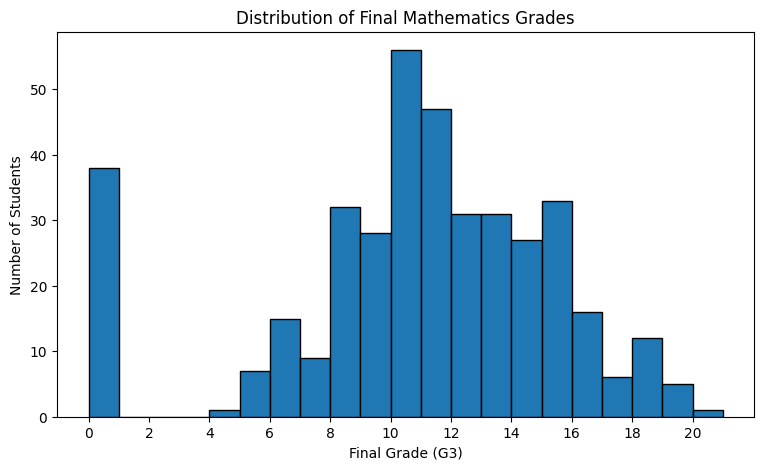

In [3]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["G3"],
    bins=range(0, 22),
    edgecolor="black"
)

plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.xticks(range(0, 21, 2))

plt.show()


In [4]:
# Calculate average final grade for each study-time group

study_summary = (
    df.groupby("studytime")["G3"]
    .agg(["mean", "count"])
    .reindex([1, 2, 3, 4])
)

study_summary.columns = [
    "Average Final Grade",
    "Number of Students"
]

display(study_summary.round(2))

,Average Final Grade,Number of Students
studytime,,
1,10.05,105
2,10.17,198
3,11.40,65
4,11.26,27


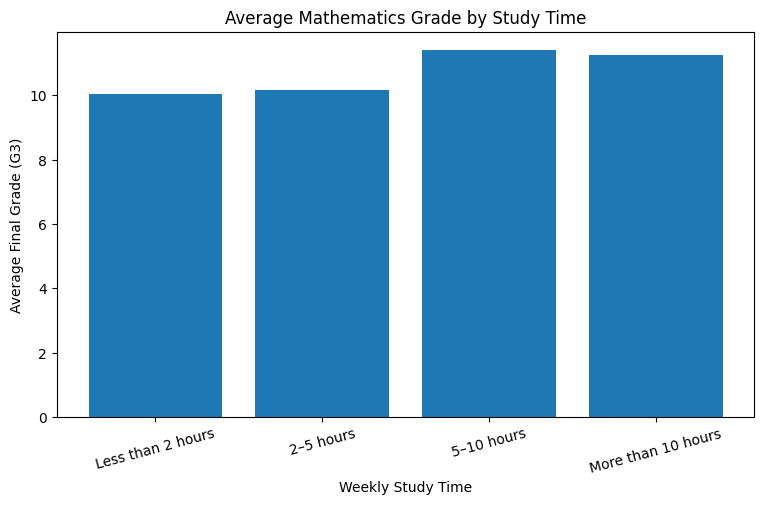

In [5]:
# Visualise average final grade by weekly study time

labels = [
    "Less than 2 hours",
    "2–5 hours",
    "5–10 hours",
    "More than 10 hours"
]

plt.figure(figsize=(9, 5))

plt.bar(
    labels,
    study_summary["Average Final Grade"]
)

plt.title("Average Mathematics Grade by Study Time")
plt.xlabel("Weekly Study Time")
plt.ylabel("Average Final Grade (G3)")
plt.xticks(rotation=15)

plt.show()

In [8]:
grade_counts = df["G3"].value_counts().sort_index()

print("Number of students at each final grade:")
display(grade_counts.to_frame("Number of Students"))

print("Most common grade(s):")
display(grade_counts[grade_counts == grade_counts.max()])

Number of students at each final grade:


,Number of Students
G3,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47


Most common grade(s):


,count
G3,
10,56


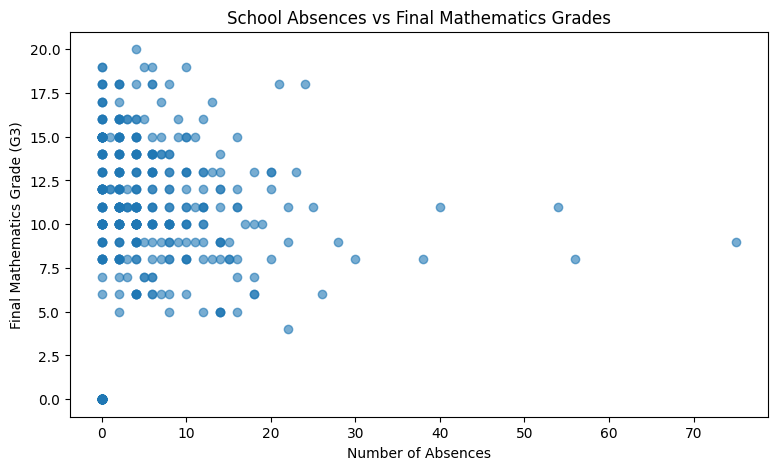

In [6]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["absences"],
    df["G3"],
    alpha=0.6
)

plt.title("School Absences vs Final Mathematics Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Mathematics Grade (G3)")

plt.show()

In [7]:
# Examine correlations between numerical variables

selected_columns = [
    "studytime",
    "absences",
    "failures",
    "G1",
    "G2",
    "G3"
]

correlation_matrix = df[selected_columns].corr()

display(correlation_matrix.round(2))

# Show correlations with final mathematics grade

grade_correlations = (
    correlation_matrix["G3"]
    .drop("G3")
    .sort_values(ascending=False)
)

display(
    grade_correlations.to_frame(
        "Correlation with Final Grade"
    ).round(2)
)

,studytime,absences,failures,G1,G2,G3
studytime,1.00,-0.06,-0.17,0.16,0.14,0.10
absences,-0.06,1.00,0.06,-0.03,-0.03,0.03
failures,-0.17,0.06,1.00,-0.35,-0.36,-0.36
G1,0.16,-0.03,-0.35,1.00,0.85,0.80
G2,0.14,-0.03,-0.36,0.85,1.00,0.90
G3,0.10,0.03,-0.36,0.80,0.90,1.00


,Correlation with Final Grade
G2,0.90
G1,0.80
studytime,0.10
absences,0.03
failures,-0.36


# Key Findings

## 1. Dataset Overview
- Number of students: 395
- Number of columns: 33
- Missing values: 0
- Duplicate rows: 0

## 2. Grade Distribution
The final mathematics grades ranged from 0 to 20. The most common grade was 10, achieved by 56 students, followed by 11, achieved by 47 students. Most students (approximately 72%) scored between 8 and 15. An interesting observation was that 38 students received a grade of 0, while only 18 students scored between 18 and 20. Overall, the grades were mainly concentrated in the middle range, with relatively few students achieving the highest grades.

## 3. Study Time and Performance
Students who studied between 5 and 10 hours per week had the highest average final mathematics grade, while those who studied less than 2 hours had the lowest average. Interestingly, students who studied for more than 10 hours did not have the highest average grade. This suggests that more study time does not necessarily correspond to a higher average grade in this dataset.

## 4. Absences and Performance
Most students with fewer than 10 absences had relatively good final mathematics grades. Students with more than 30–40 absences generally had lower grades. However, there were a few students with approximately 20–30 absences who still achieved reasonably good grades. This shows that the relationship is not identical for every student.

## 5. Correlation Analysis
G2 (second-period grade) had the strongest positive correlation with G3 (final grade), with a correlation coefficient of approximately +0.9049. G1 (first-period grade) also showed a strong positive correlation of approximately +0.8015.

Previous class failures had the strongest negative correlation with G3, with a correlation coefficient of approximately -0.3604. This suggests that students with more previous class failures tended to achieve lower final grades.

# Conclusion

The average grades by study-time group are approximately:
Weekly study time	Average G3
Less than 2 hours	10.05
2–5 hours	10.17
5–10 hours	11.40
More than 10 hours	11.26
One of the most interesting observations was that students who studied between 5 and 10 hours per week achieved the highest average final grade. Interestingly, students who studied more than 10 hours had a slightly lower average grade. This challenges the assumption that more study time always results in better academic performance. However, the difference was small, and the analysis does not establish that additional study time causes lower grades.
# Limitations

This dataset represents students from two Portuguese schools.
The results may not generalise to students in other countries.
The observed relationships do not establish causation.
Limited sample size: The mathematics dataset contains only 395 students, which may not adequately represent the wider student population.
Categorised study time: Study time is recorded in four broad categories rather than exact hours, limiting the precision of the analysis.